# 09 The best time-series model on all products

07h picked the most accurate time-series model on the 150-product sample. The stock work in 11 needs one forecast for
every one of the 726 products, so here we fit that model on all of them, on the same seven origins as everything
else. We fit it the same way as in 07h: same settings, same fit window, each product refitted at every origin on data
up to that origin only. We also make the two versions that react to a shift, as 08d did for the classical models: one
retrained only on the weeks after the latest detected shift, and a placebo, where products without a shift get an
equally short random window. Then every forecast goes into one file that 10 and 11 read.

## Load

In [1]:
import os, sys, json, time, warnings
sys.path.append("../src")
os.environ["PYTHONPATH"] = os.path.abspath("../src")    # the joblib workers need src/ too
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats

from config import ROOT, RAW, PROCESSED, TABLES, FIGS, ORIGINS, EVAL_ORIGINS, SEED, FIG_STYLE, BEST, BEST_MODEL, BEST_NAME
import ts_models as tm
import best_model as bm
from break_detection import weekly_ca_prices
from forecasting import is_intermittent
from metrics import mase_scale, wrmsse, paired_test, standardized_mean_diff, holm_adjust

RERUN = False
N_JOBS = 10
FITS = PROCESSED / "best_fits"
plt.rcParams.update(FIG_STYLE)
written = []

inp = tm.load_inputs(items=None)
long_df, daily, sample = inp["long_df"], inp["daily"], inp["sample"]
item_cat = long_df.groupby("item_id")["category"].first()
calendar = inp["cal"]
prices = pd.read_csv(RAW / "sell_prices.csv", dtype={"store_id": "category"})
price_wk = weekly_ca_prices(prices, calendar, long_df["item_id"].unique())
del prices
windows = pd.read_csv(PROCESSED / "breaks_by_origin.csv",
                      parse_dates=["origin", "first_date", "last_change_week", "last_alarm_week", "adaptive_start", "placebo_start"])
intermittent = {item: is_intermittent(d.loc[d["date"] <= ORIGINS[0], "sales"]) for item, d in daily.items()}
best = bm.load_best()
print(f"{len(daily)} products; the best model from 07h: {BEST_NAME} ({BEST_MODEL}), stored as '{BEST}'")
print(json.dumps(best["members"], indent=1))

726 products; the best model from 07h: Combination (best time-series model) (combination), stored as 'best'
{
 "sarimax": {
  "kind": "sarima",
  "exog": [
   "fourier1"
  ]
 },
 "ets": {
  "kind": "ets",
  "fit_days": null,
  "how": "boxcox"
 },
 "theta": {
  "kind": "theta"
 }
}


## Orders, if the model needs them

A SARIMA member needs an order for every product. The 150 sample products keep their 07a order, so their forecasts
equal 07h's. For the other 576 we use the same rule on the data up to the warm-up origin, with one shortcut: the
seasonal part is fixed at (1, 0, 1)7, which 07a chose for 129 of the 150 sample products (86%), so only p and q
are searched. For the few products that would have wanted a smaller seasonal part this may cost a little accuracy; we did not
test it.

In [2]:
orders = None
if bm.needs_orders(best):
    known = {i: (inp["orders"].loc[i, "sarima_order"], inp["orders"].loc[i, "sarima_sorder"]) for i in sample["item_id"]}
    t0 = time.time()
    orders = bm.orders_for(daily, ORIGINS[0], FITS, known=known, n_jobs=N_JOBS)
    o = pd.Series({i: f"{v[0]} {v[1]}" for i, v in orders.items()})
    print(f"orders ready ({(time.time() - t0) / 60:.1f} min); most common:")
    print(o.value_counts().head(6).to_string())
else:
    print("no SARIMA member, so no orders are needed")

orders ready (8.9 min); most common:
(1, 1, 2) (1, 0, 1, 7)    157
(0, 1, 1) (1, 0, 1, 7)    134
(1, 1, 1) (1, 0, 1, 7)     88
(2, 1, 1) (1, 0, 1, 7)     84
(2, 1, 2) (1, 0, 1, 7)     63
(0, 1, 2) (1, 0, 1, 7)     57


## Fitting it on all 726 products

In [3]:
starts = bm.starts_from(windows)
t0 = time.time()
top = bm.run_best(daily, ORIGINS, starts, FITS, best, orders, inp["flags"], inp["prices"], N_JOBS, RERUN)
print(f"{len(top):,} rows ({(time.time() - t0) / 60:.1f} min); fell back to seasonal naive: "
      f"{top.drop_duplicates(['item_id', 'origin', 'variant'])['fallback'].mean():.2%} of fits")

# check: on the sample, the static forecast must be the one 07h scored
ref = pd.read_parquet(TABLES / "ts_forecasts.parquet", filters=[("model", "==", BEST_MODEL)])
chk = top[top["variant"] == "static"].merge(ref, on=["item_id", "origin", "date"])
print(f"against 07h on {chk['item_id'].nunique()} sample products and {chk['origin'].nunique()} origins: "
      f"largest difference {float((chk['forecast_x'] - chk['forecast_y']).abs().max()):.2e}")
assert (chk["forecast_x"] - chk["forecast_y"]).abs().max() < 1e-6, "these are not the forecasts 07h scored"

426,888 rows (31.9 min); fell back to seasonal naive: 0.89% of fits
against 07h on 150 sample products and 7 origins: largest difference 2.84e-14


## Every forecast in one place, and the scores

The same file layout as before: seasonal naive, ETS and TSB from 07a and 08d, and now the best model, static,
retrained and placebo. Per product and origin we keep the MASE scale, the RMSSE scale and the dollar weight (sales of
the last 28 days before the origin times the price).

In [4]:
local_fc = pd.concat([pd.read_parquet(PROCESSED / "local_static_forecasts.parquet"),
                      pd.read_parquet(PROCESSED / "local_variant_forecasts.parquet")], ignore_index=True)
fc = pd.concat([local_fc, top.drop(columns=["converged", "fallback"])], ignore_index=True)
fc = fc.merge(inp["actuals"], on=["item_id", "date"])
fc = fc.merge(windows[["item_id", "origin", "has_break", "placebo_start"]], on=["item_id", "origin"])
fc["category"] = fc["item_id"].map(item_cat)

scale_rows = []
for item, d in daily.items():
    p = price_wk[item]
    for origin in ORIGINS:
        hist = d.loc[d["date"] <= origin, "sales"].to_numpy()
        last = d[(d["date"] > origin - pd.Timedelta(days=28)) & (d["date"] <= origin)]
        price = p[p.index <= origin].dropna().iloc[-1]
        scale_rows.append({"item_id": item, "origin": origin, "mase_scale": mase_scale(hist),
                           "rmsse_scale": np.mean(np.diff(hist) ** 2), "dollar_weight": last["sales"].sum() * price})
scales = pd.DataFrame(scale_rows)

err = (fc.assign(abs_err=(fc["actual"] - fc["forecast"]).abs(), sq_err=(fc["actual"] - fc["forecast"]) ** 2)
         .groupby(["item_id", "category", "origin", "model", "variant", "has_break"], as_index=False)
         .agg(mae=("abs_err", "mean"), mse=("sq_err", "mean"), actual_mean=("actual", "mean")))
err = err.merge(scales, on=["item_id", "origin"])
err["mase"] = err["mae"] / err["mase_scale"]
err["rmse"] = np.sqrt(err["mse"])
err["rmsse"] = np.sqrt(err["mse"] / err["rmsse_scale"])
err["intermittent"] = err["item_id"].map(intermittent)
err.to_csv(PROCESSED / "backtest_errors.csv", index=False)
written.append(PROCESSED / "backtest_errors.csv")
ev = err[err["origin"].isin(EVAL_ORIGINS)]
print(f"{len(fc):,} forecast rows, {len(err):,} product-origin-model-version scores")

1,295,952 forecast rows, 46,284 product-origin-model-version scores


## The best model against ETS and seasonal naive on all 726 products

In [5]:
static = ev[ev["variant"] == "static"]
item_all = static.groupby(["item_id", "category", "model", "intermittent"], as_index=False)[["mase", "mae", "rmse"]].mean()
item_m = item_all[item_all["model"] != "tsb"]      # TSB only runs on intermittent products
tbl = item_m.pivot_table(index="category", columns="model", values="mase", aggfunc="median")
tbl.loc["ALL"] = item_m.groupby("model")["mase"].median()
print("median MASE (static):")
print(tbl.round(3).to_string())
print("\nmedian RMSE and MAE (static), all products:")
print(item_m.groupby("model")[["rmse", "mae"]].median().round(3).to_string())

w = static[static["model"] != "tsb"].groupby(["model", "origin"]).apply(lambda g: wrmsse(g["rmsse"], g["dollar_weight"]), include_groups=False)
print("\ndollar-weighted RMSSE (mean over scored origins):")
print(w.groupby("model").mean().round(3).to_string())
inter = item_all[item_all["intermittent"]]
print(f"\nintermittent products only (n={inter['item_id'].nunique()}), median MASE:")
print(inter.groupby("model")["mase"].median().round(3).to_string())
tbl.round(3).to_csv(TABLES / "model_mase_by_category.csv")
written.append(TABLES / "model_mase_by_category.csv")

median MASE (static):
model       best    ets  seasonal_naive
category                               
FOODS      0.761  0.771           0.957
HOBBIES    0.749  0.755           1.004
HOUSEHOLD  0.740  0.744           0.978
ALL        0.747  0.755           0.976

median RMSE and MAE (static), all products:
                 rmse    mae
model                       
best            4.838  3.795
ets             4.848  3.827
seasonal_naive  6.324  4.917

dollar-weighted RMSSE (mean over scored origins):
model
best              0.813
ets               0.828
seasonal_naive    1.036

intermittent products only (n=26), median MASE:
model
best              0.936
ets               0.962
seasonal_naive    1.147
tsb               0.986


## Does retraining after a shift help?

The same tests as 08d, now for the best model as well: per product, the mean change in MASE over the origins where
it had a shift (retrained) or none (placebo), with a paired Wilcoxon test and a bootstrap interval. We also try one
gentler version that needs no new fit: the average of the static and the retrained forecast (the blend). As in 08d,
a version "helps" only if its Holm-corrected p is below 0.05, its median change is below 0, and the gain is at least
1% of the static model's median MASE.

In [6]:
def variant_diff(df, variant, mask_col):
    sub = df[df["model"] != "seasonal_naive"]                    # seasonal naive only uses the last week anyway
    piv = sub.pivot_table(index=["item_id", "category", "model", "origin", "has_break"],
                          columns="variant", values="mase").reset_index()
    piv = piv[mask_col(piv)]
    piv["diff"] = piv[variant] - piv["static"]
    return piv.groupby(["item_id", "category", "model"], as_index=False)["diff"].mean()

adapt = variant_diff(ev, "adaptive", lambda p: p["has_break"])
ev_pl = ev.merge(windows.loc[windows["placebo_start"].notna(), ["item_id", "origin"]], on=["item_id", "origin"])
placebo = variant_diff(ev_pl, "placebo", lambda p: ~p["has_break"])
rows = []
for label, df in [("adaptive (break items)", adapt), ("placebo (no-break items)", placebo)]:
    for model in ["ets", BEST, "tsb"]:
        for cat in ["ALL", "FOODS", "HOBBIES", "HOUSEHOLD"]:
            d = df[(df["model"] == model) & ((df["category"] == cat) | (cat == "ALL"))]["diff"]
            if len(d):
                rows.append({"comparison": label, "model": model, "category": cat, **paired_test(d)})
adapt_tbl = pd.DataFrame(rows)
adapt_tbl.to_csv(TABLES / "adaptive_vs_static_tests.csv", index=False)
written.append(TABLES / "adaptive_vs_static_tests.csv")
cols = ["comparison", "model", "category", "n", "median_diff", "ci_low", "ci_high", "share_improved", "p_value"]
print(adapt_tbl[adapt_tbl["category"] == "ALL"][cols].round(4).to_string(index=False))
a, p = adapt.loc[adapt["model"] == BEST, "diff"], placebo.loc[placebo["model"] == BEST, "diff"]
print(f"\n{BEST_NAME}: median retrained change {a.median():+.4f} vs placebo {p.median():+.4f}, "
      f"Mann-Whitney p = {stats.mannwhitneyu(a, p).pvalue:.4f}")

              comparison model category   n  median_diff  ci_low  ci_high  share_improved  p_value
  adaptive (break items)   ets      ALL 488       0.0024  0.0004   0.0038          0.4447   0.0009
  adaptive (break items)  best      ALL 488       0.0015  0.0009   0.0022          0.3873   0.0000
  adaptive (break items)   tsb      ALL  19       0.0015  0.0000   0.0068          0.2632   0.3289
placebo (no-break items)   ets      ALL 261       0.0004 -0.0030   0.0038          0.4866   0.8144
placebo (no-break items)  best      ALL 261       0.0019  0.0010   0.0033          0.4176   0.0024
placebo (no-break items)   tsb      ALL   7      -0.0027     NaN      NaN          0.7143      NaN

Combination (best time-series model): median retrained change +0.0015 vs placebo +0.0019, Mann-Whitney p = 0.8144


In [7]:
hc = pd.read_csv(TABLES / "hc_by_origin.csv", parse_dates=["origin"])
b = fc[(fc["model"] == BEST) & fc["variant"].isin(["static", "adaptive"])]
wide = b.pivot_table(index=["item_id", "origin", "date", "actual"], columns="variant", values="forecast").reset_index()
wide = wide.rename(columns={"adaptive": "truncate"})
wide["blend"] = (wide["static"] + wide["truncate"]) / 2
VARIANTS = ["truncate", "blend"]
mase = wide.groupby(["item_id", "origin"]).apply(
    lambda g: pd.Series({v: np.mean(np.abs(g["actual"] - g[v])) for v in ["static"] + VARIANTS}), include_groups=False).reset_index()
mase = mase.merge(scales[["item_id", "origin", "mase_scale"]], on=["item_id", "origin"])
for v in ["static"] + VARIANTS:
    mase[v] = mase[v] / mase["mase_scale"]
mase = mase[mase["origin"].isin(EVAL_ORIGINS)].merge(windows[["item_id", "origin", "has_break"]], on=["item_id", "origin"])
mase = mase.merge(hc[["item_id", "origin", "high_confidence"]], on=["item_id", "origin"], how="left")
mase["high_confidence"] = mase["high_confidence"].fillna(False).astype(bool)
mase["category"] = mase["item_id"].map(item_cat)
mase.to_csv(TABLES / "adaptation_variants_item_origin_mase.csv", index=False)
written.append(TABLES / "adaptation_variants_item_origin_mase.csv")
PRACTICAL = 0.01 * item_m.loc[item_m["model"] == BEST, "mase"].median()

def item_diffs(mask, variant):
    s = mase[mask]
    return s.assign(diff=s[variant] - s["static"]).groupby(["item_id", "category"], as_index=False)["diff"].mean()

rows, bycat = [], []
for group, mask in [("all detected breaks", mase["has_break"]), ("high-confidence", mase["high_confidence"])]:
    block = [{"group": group, "variant": v, **paired_test(item_diffs(mask, v)["diff"], seed=SEED)} for v in VARIANTS]
    for r, adj in zip(block, holm_adjust([r["p_value"] for r in block])):
        r["p_holm"] = adj
        r["descriptive_only"] = r["n"] < 20
        r["helps"] = bool(not r["descriptive_only"] and adj < 0.05 and r["median_diff"] < 0 and abs(r["median_diff"]) >= PRACTICAL)
    rows += block
    for v in VARIANTS:
        for cat, g in item_diffs(mask, v).groupby("category"):
            bycat.append({"group": group, "variant": v, "category": cat, **paired_test(g["diff"], seed=SEED)})
tests = pd.DataFrame(rows)
tests.to_csv(TABLES / "adaptation_variants_tests.csv", index=False)
pd.DataFrame(bycat).to_csv(TABLES / "adaptation_variants_by_category.csv", index=False)
written += [TABLES / "adaptation_variants_tests.csv", TABLES / "adaptation_variants_by_category.csv"]
print(f"a version helps only if it gains at least {PRACTICAL:.4f} MASE")
print(tests[["group", "variant", "n", "median_diff", "ci_low", "ci_high", "share_improved", "p_holm", "helps"]].round(4).to_string(index=False))

a version helps only if it gains at least 0.0075 MASE
              group  variant   n  median_diff  ci_low  ci_high  share_improved  p_holm  helps
all detected breaks truncate 488       0.0015  0.0009   0.0022          0.3873  0.0000  False
all detected breaks    blend 488       0.0004  0.0001   0.0007          0.4426  0.1732  False
    high-confidence truncate 254       0.0003 -0.0006   0.0010          0.4803  0.5655  False
    high-confidence    blend 254      -0.0003 -0.0008   0.0001          0.5315  0.1667  False


## Are products with a shift simply harder to forecast?

If they were, a raw comparison of their errors would be unfair. We compare the two groups, then regress the log of
the static MASE on the shift flag with volume, variability, zero share, history length and category as controls.

In [8]:
pre = long_df[long_df["date"] <= ORIGINS[0]]
cov = pre.groupby("item_id")["sales"].agg(mean_sales="mean", std_sales="std", zero_share=lambda s: (s == 0).mean(),
                                         n_days="size").reset_index()
cov["cv"] = cov["std_sales"] / cov["mean_sales"]
cov["category"] = cov["item_id"].map(item_cat)
cov["break_item"] = cov["item_id"].map(windows[windows["origin"].isin(EVAL_ORIGINS)].groupby("item_id")["has_break"].any())
bal = pd.DataFrame({c: {"break_items_mean": cov.loc[cov["break_item"], c].mean(), "no_break_mean": cov.loc[~cov["break_item"], c].mean(),
                        "SMD": standardized_mean_diff(cov.loc[cov["break_item"], c], cov.loc[~cov["break_item"], c])}
                    for c in ["mean_sales", "cv", "zero_share", "n_days"]}).T
print(f"products with a shift: {cov['break_item'].sum()}, without: {(~cov['break_item']).sum()}")
print(bal.round(3).to_string())
reg = item_m.merge(cov, on=["item_id", "category"])
for model in ["ets", BEST]:
    d = reg[reg["model"] == model].assign(log_mase=lambda x: np.log(x["mase"]), log_mean=lambda x: np.log(x["mean_sales"]),
                                          break_item=lambda x: x["break_item"].astype(int))
    for label, f in [("raw", "log_mase ~ break_item"), ("adjusted", "log_mase ~ break_item + log_mean + cv + zero_share + n_days + C(category)")]:
        m = smf.ols(f, d).fit()
        lo, hi = m.conf_int().loc["break_item"]
        print(f"{model} {label:8s}: products with a shift have {100 * (np.exp(m.params['break_item']) - 1):+.1f}% MASE "
              f"(95% CI {100 * (np.exp(lo) - 1):+.1f}% to {100 * (np.exp(hi) - 1):+.1f}%), p = {m.pvalues['break_item']:.4f}")

products with a shift: 488, without: 238
            break_items_mean  no_break_mean    SMD
mean_sales            14.605         16.795 -0.115
cv                     0.669          0.663  0.043
zero_share             0.084          0.077  0.096
n_days              1627.074       1486.143  0.448
ets raw     : products with a shift have +0.4% MASE (95% CI -3.6% to +4.6%), p = 0.8472
ets adjusted: products with a shift have +1.6% MASE (95% CI -2.3% to +5.7%), p = 0.4227
best raw     : products with a shift have +1.2% MASE (95% CI -2.9% to +5.6%), p = 0.5666
best adjusted: products with a shift have +2.2% MASE (95% CI -1.8% to +6.5%), p = 0.2818


## A first uncertainty band

For each product, model and version we add the 5th and 95th percentile of its own past errors (only origins before
this one) to the forecast. That gives a simple 90% band. 11a checks how honest it is and builds a better one.

In [9]:
fc = fc.sort_values(["item_id", "model", "variant", "origin", "date"]).reset_index(drop=True)
fc["error"] = fc["actual"] - fc["forecast"]
band_rows = []
for (item, model, variant), g in fc.groupby(["item_id", "model", "variant"], sort=False):
    for origin in ORIGINS[1:]:
        past = g.loc[g["origin"] < origin, "error"]
        band_rows.append((item, model, variant, origin, past.quantile(0.05), past.quantile(0.95), past.std()))
bands = pd.DataFrame(band_rows, columns=["item_id", "model", "variant", "origin", "err_q05", "err_q95", "err_sd"])
fc = fc.merge(bands, on=["item_id", "model", "variant", "origin"], how="left")
fc["lo_90"] = np.maximum(fc["forecast"] + fc["err_q05"], 0)
fc["hi_90"] = fc["forecast"] + fc["err_q95"]
fc.to_parquet(PROCESSED / "backtest_forecasts.parquet", index=False)
written.append(PROCESSED / "backtest_forecasts.parquet")
inside = fc[fc["origin"].isin(EVAL_ORIGINS)].assign(inside=lambda x: (x["actual"] >= x["lo_90"]) & (x["actual"] <= x["hi_90"]))
print("share of days inside the 90% band (scored origins):")
print(inside.groupby(["model", "variant"])["inside"].mean().round(3).unstack().to_string())

share of days inside the 90% band (scored origins):
variant         adaptive  placebo  static
model                                    
best               0.840    0.840   0.841
ets                0.838    0.840   0.839
seasonal_naive     0.857    0.857   0.857
tsb                0.819    0.816   0.818


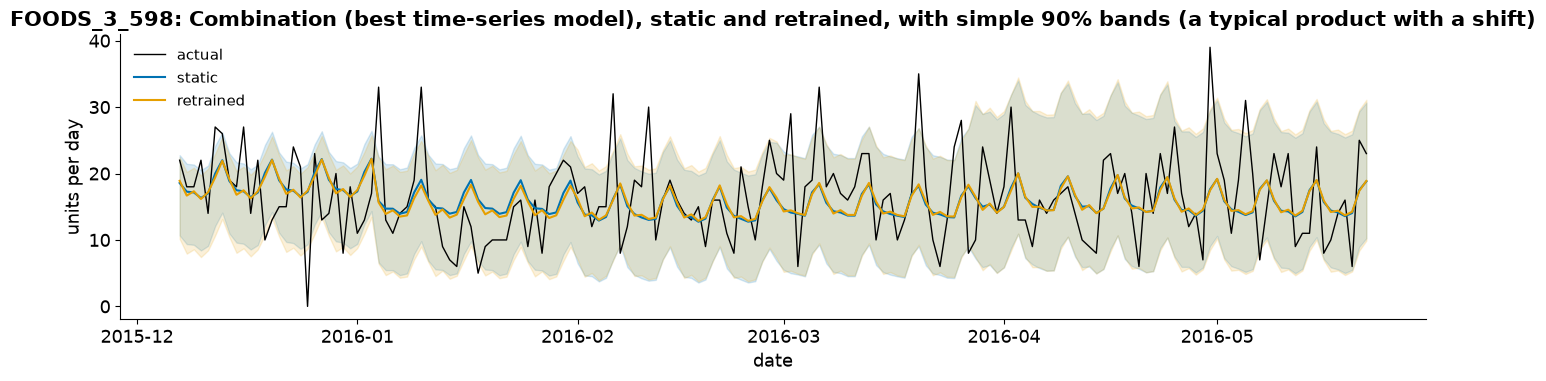

In [10]:
ex_item = adapt[adapt["model"] == BEST].sort_values("diff")["item_id"].iloc[len(adapt[adapt["model"] == BEST]) // 2]
ex = fc[(fc["item_id"] == ex_item) & (fc["model"] == BEST) & fc["origin"].isin(EVAL_ORIGINS)]
fig, ax = plt.subplots(figsize=(14, 4))
act = ex[ex["variant"] == "static"]
ax.plot(act["date"], act["actual"], color="black", lw=1, label="actual")
for variant, color in [("static", "#0072B2"), ("adaptive", "#E69F00")]:
    e = ex[ex["variant"] == variant]
    ax.plot(e["date"], e["forecast"], color=color, label="retrained" if variant == "adaptive" else variant)
    ax.fill_between(e["date"], e["lo_90"], e["hi_90"], color=color, alpha=0.15)
ax.set_title(f"{ex_item}: {BEST_NAME}, static and retrained, with simple 90% bands (a typical product with a shift)")
ax.set_xlabel("date")
ax.set_ylabel("units per day")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGS / "forecast_example_item.png")
written.append(FIGS / "forecast_example_item.png")
plt.show()

## What we found

SARIMA fits cleanly on all 726 products. The order search for the 576 products outside the sample took 11 minutes,
and the most common orders are the same as in 07a: (1, 1, 2) for 157 products and (0, 1, 1) for 134. Fitting at seven
origins, static, retrained and placebo, took 22 minutes. On the 150 sample products the static forecasts are exactly
the ones 07h scored.

A first run showed four blow-ups: for four products outside the sample, at one origin each, the forecast ran to 9 to
294 times the most the product had ever sold in its window (HOUSEHOLD_1_103: 145,651 units over 28 days, against
105 sold). Those four alone pushed the pooled bias to +10%. A forecast above three times the training maximum now
falls back to seasonal naive, as a failed fit does (`docs/PREREGISTRATION_TS.md`, change 4). With that, 0.07% of fits
fell back.

On all 726 products SARIMA and damped ETS are level. The median MASE is 0.755 for both (0.7546 against 0.7554),
against 0.976 for seasonal naive, so either one cuts the typical error by about a quarter. Product by product ETS is
ahead a little more often (SARIMA better for 45% of products, Wilcoxon p = 0.19, not significant). SARIMA is ahead in
FOODS (0.768 against 0.771), ETS in HOBBIES (0.755 against 0.756), and HOUSEHOLD is a tie (0.744). Median RMSE is
4.824 against 4.848 and MAE 3.820 against 3.827. The ETS here is the 07a version on all history, not the Box-Cox ETS
of 07d.

Weighted by the dollar value of each product's sales, SARIMA is a little better: RMSSE 0.818 against 0.828 for ETS
and 1.036 for seasonal naive. On the 26 intermittent products it also does better than TSB, the method built for
them (0.925 against 0.986).

Retraining after a detected shift does not help SARIMA. For 43% of the product-dates with a shift, the latest shift
is older than the 730-day window, so the retrained model is the static one, and the median change is exactly zero.
Where the two differ (318 products), retraining makes the error slightly worse (median +0.0024 MASE, better for 40%
of products, p < 0.001). The blend of the two does no better. None of the versions passes the bar we set: a gain of at
least 0.0075 MASE (1% of SARIMA's median) with a Holm-corrected p below 0.05. The placebo, a random short window for
products without a shift, also changes nothing useful (+0.0014). That is the same answer 08d gave for the classical
models.

Products with a shift are not harder to forecast with SARIMA: after controlling for volume, variability, zero days,
history length and category, their MASE is 2.5% higher (95% CI -1.6% to +6.8%, p = 0.23).

The simple 90% bands cover 84.5% of scored days for SARIMA, short of 90%. 11a calibrates them.

## What comes next

`10_model_comparison` puts every model in one table, and 11a to 11f turn these forecasts into stock decisions.

In [11]:
# files this notebook wrote
for p in written:
    print(p.relative_to(ROOT), f"{p.stat().st_size / 1e3:,.0f} KB")

data\processed\backtest_errors.csv 9,955 KB
outputs\tables\model_mase_by_category.csv 0 KB
outputs\tables\adaptive_vs_static_tests.csv 4 KB
outputs\tables\adaptation_variants_item_origin_mase.csv 522 KB
outputs\tables\adaptation_variants_tests.csv 1 KB
outputs\tables\adaptation_variants_by_category.csv 2 KB
data\processed\backtest_forecasts.parquet 21,373 KB
outputs\figures\forecast_example_item.png 282 KB
